# 16 · Autoencoders and Representation Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/16-autoencoders/16_autoencoders.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-16-autoencoders.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 16](https://github.com/anuxlab/deep-learning-systems/wiki/Module-16) |
| **Level** | Intermediate |
| **Typical CPU runtime** | ~1–2 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 01, 07 |

## What you will do

- Show that a linear undercomplete autoencoder learns the PCA subspace.
- Train non-linear, sparse, denoising and contractive autoencoders on digits.
- Inspect latent geometry (2-D embedding) and test downstream usefulness with a linear probe / kNN.
- Interpret the reconstruction-vs-representation trade-off.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:16:05 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926805324
          commit: a4aa24e57dfd9f88471149adff810366178f90be


## 1 · The autoencoder objective
An encoder $z=f_\theta(x)$ and decoder $\hat x=g_\phi(z)$ are trained to minimise reconstruction error $\|x-g(f(x))\|^2$. With a **bottleneck** ($\dim z<\dim x$) the network must keep only the most useful information. We use scikit-learn's digits (1,797 images of 8×8 = 64 pixels in [0,1]).

In [2]:
from sklearn.datasets import load_digits
D = load_digits(); X = torch.tensor(D.data / 16., dtype=torch.float32); y = D.target
idx = np.random.default_rng(0).permutation(len(X)); tr, te = idx[:1300], idx[1300:]
Xtr, Xte = X[tr], X[te]; ytr, yte = y[tr], y[te]; print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))
def fit(model, loss_fn, epochs=60, lr=3e-3, noise=0.0, bs=64, seed=0):
    torch.manual_seed(seed); o = torch.optim.Adam(model.parameters(), lr); hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for s in range(0, len(perm), bs):
            xb = Xtr[perm[s:s + bs]]; xin = (xb + noise * torch.randn_like(xb)).clamp(0, 1) if noise else xb
            loss = loss_fn(model, xin, xb); o.zero_grad(); loss.backward(); o.step()
        with torch.no_grad(): hist.append(F.mse_loss(model(Xte), Xte).item())
    return hist
plain_loss = lambda m, xin, xt: F.mse_loss(m(xin), xt)
class AE(nn.Module):
    def __init__(s, k, hidden=64, act=nn.ReLU, linear=False):
        super().__init__()
        s.enc = nn.Linear(64, k) if linear else nn.Sequential(nn.Linear(64, hidden), act(), nn.Linear(hidden, k))
        s.dec = nn.Linear(k, 64) if linear else nn.Sequential(nn.Linear(k, hidden), act(), nn.Linear(hidden, 64), nn.Sigmoid())
    def forward(s, x): return s.dec(s.enc(x))
    def encode(s, x): return s.enc(x)

train (1300, 64) test (497, 64)


## 2 · Linear autoencoder = PCA
For MSE loss, a linear AE with $k$ units attains the same minimum as the best rank-$k$ approximation (PCA), and its decoder spans the **same subspace** (though the individual basis vectors may be any basis of it). We compare reconstruction error and the principal angles between the subspaces.

In [3]:
from sklearn.decomposition import PCA
from scipy.linalg import subspace_angles
k = 8; pca = PCA(k).fit(Xtr.numpy()); mse_pca = np.mean((pca.inverse_transform(pca.transform(Xte.numpy())) - Xte.numpy()) ** 2)
mu = Xtr.mean(0); lin = AE(k, linear=True)
class Centered(nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return s.m(x - mu) + mu
lin_c = Centered(lin); hist = fit(lin_c, plain_loss, epochs=300, lr=1e-2); mse_lin = hist[-1]
print(f"test MSE  PCA(k={k}): {mse_pca:.5f}   linear AE: {mse_lin:.5f}")
ang = np.degrees(subspace_angles(pca.components_.T, lin.dec.weight.detach().numpy())); print("principal angles between PCA subspace and AE decoder subspace (deg):", ang.round(1))
check(mse_lin < mse_pca * 1.15, "linear AE reaches (almost) the PCA reconstruction error")
check(ang.max() < 25, "the AE decoder spans (nearly) the PCA subspace")
METRICS.update(mse_pca=mse_pca, mse_linear_ae=mse_lin)

test MSE  PCA(k=8): 0.02425   linear AE: 0.02431
principal angles between PCA subspace and AE decoder subspace (deg): [2.  1.6 1.4 1.2 1.1 0.8 0.8 0.7]
  ✅ linear AE reaches (almost) the PCA reconstruction error
  ✅ the AE decoder spans (nearly) the PCA subspace


## 3 · Non-linear autoencoder and the effect of the bottleneck
Non-linear encoders can model curved manifolds and beat PCA at the same $k$. We vary the code size and compare with PCA.

k=  2  AE 0.03707  PCA 0.05310


k=  4  AE 0.02251  PCA 0.03794


k=  8  AE 0.01462  PCA 0.02425


k= 16  AE 0.00743  PCA 0.01139


k= 32  AE 0.00521  PCA 0.00266
18:16:22 | INFO | ae_bottleneck_sweep took 9.78s


18:16:23 | INFO | figure saved -> figures/ae_vs_pca.png


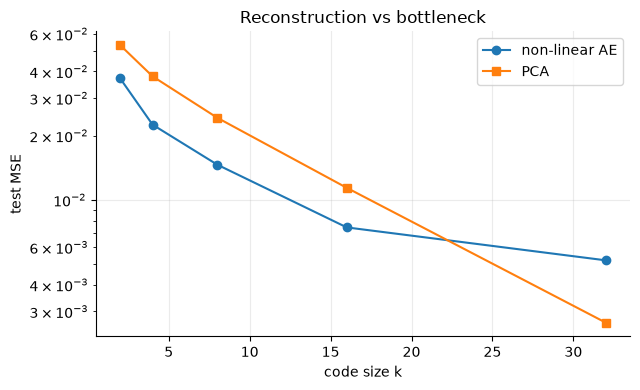

  ✅ at k=2 the non-linear AE reconstructs better than PCA


18:16:25 | INFO | figure saved -> figures/ae_reconstructions.png


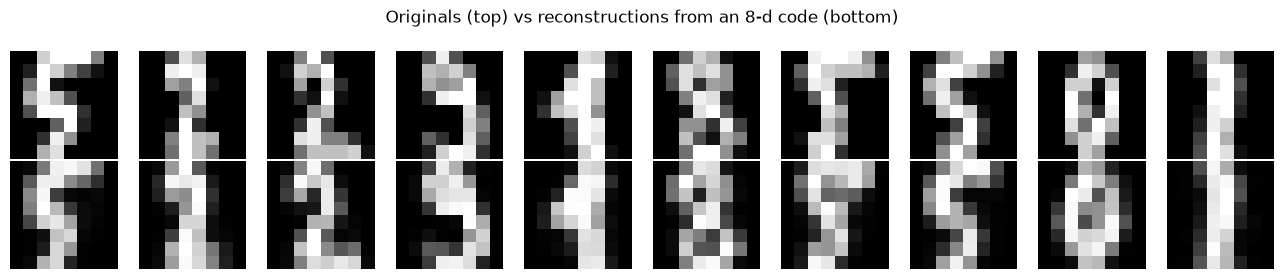

In [4]:
ks = [2, 4, 8, 16, 32]; mse_ae, mse_p = [], []
with timer("ae_bottleneck_sweep"):
    for k_ in ks:
        m = AE(k_); mse_ae.append(fit(m, plain_loss, epochs=80)[-1]); p = PCA(k_).fit(Xtr.numpy()); mse_p.append(np.mean((p.inverse_transform(p.transform(Xte.numpy())) - Xte.numpy()) ** 2))
        print(f"k={k_:3d}  AE {mse_ae[-1]:.5f}  PCA {mse_p[-1]:.5f}")
plt.semilogy(ks, mse_ae, "o-", label="non-linear AE"); plt.semilogy(ks, mse_p, "s-", label="PCA"); plt.xlabel("code size k"); plt.ylabel("test MSE"); plt.legend(); plt.title("Reconstruction vs bottleneck"); show("ae_vs_pca")
check(mse_ae[0] < mse_p[0], "at k=2 the non-linear AE reconstructs better than PCA")
ae8 = AE(8); fit(ae8, plain_loss, epochs=80)
with torch.no_grad(): rec = ae8(Xte[:10])
fig, ax = plt.subplots(2, 10, figsize=(13, 2.8))
for i in range(10): ax[0, i].imshow(Xte[i].view(8, 8), cmap="gray"); ax[1, i].imshow(rec[i].view(8, 8), cmap="gray"); ax[0, i].axis("off"); ax[1, i].axis("off")
plt.suptitle("Originals (top) vs reconstructions from an 8-d code (bottom)"); show("ae_reconstructions")

## 4 · Overcomplete + sparse autoencoder
When the code is *larger* than the input the model could learn the identity; a **sparsity penalty** $\lambda\|z\|_1$ on ReLU codes forces few active units, yielding parts-like features. We train a 256-unit code with and without the L1 penalty and compare the fraction of active units and their usefulness.

λ=0.0: active units per sample 70.2%  test MSE 0.00016


λ=0.02: active units per sample 32.6%  test MSE 0.00055
  ✅ L1 penalty makes the code much sparser


18:16:29 | INFO | figure saved -> figures/sparse_ae_atoms.png


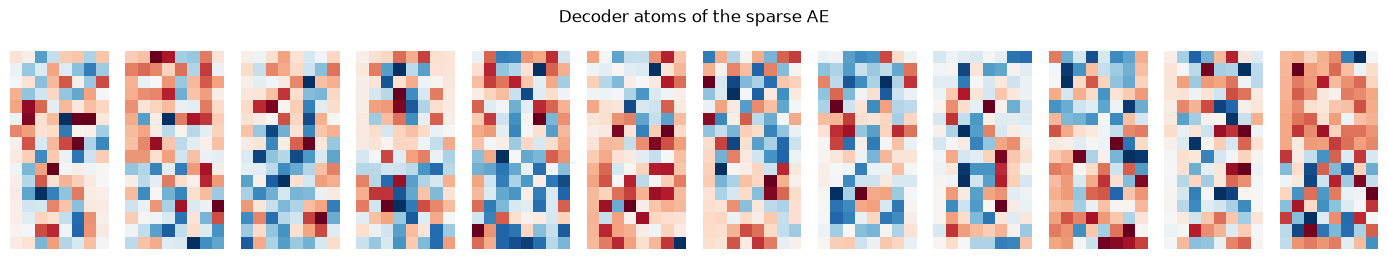

In [5]:
class SparseAE(nn.Module):
    def __init__(s, k=256): super().__init__(); s.e = nn.Linear(64, k); s.d = nn.Linear(k, 64)
    def encode(s, x): return F.relu(s.e(x))
    def forward(s, x): return s.d(s.encode(x))
def sparse_loss(lam): return lambda m, xin, xt: F.mse_loss(m(xin), xt) + lam * m.encode(xin).abs().mean()
stats = {}
for lam in [0.0, 0.02]:
    m = SparseAE(); fit(m, sparse_loss(lam), epochs=80)
    with torch.no_grad(): z = m.encode(Xte); stats[lam] = dict(active=(z > 1e-3).float().mean().item(), mse=F.mse_loss(m(Xte), Xte).item(), model=m)
    print(f"λ={lam}: active units per sample {stats[lam]['active']*100:.1f}%  test MSE {stats[lam]['mse']:.5f}")
check(stats[0.02]["active"] < stats[0.0]["active"] * .6, "L1 penalty makes the code much sparser")
W = stats[0.02]["model"].d.weight.detach().numpy().T; fig, ax = plt.subplots(2, 12, figsize=(14, 2.6))
for i, a_ in enumerate(ax.ravel()): a_.imshow(W[i].reshape(8, 8), cmap="RdBu"); a_.axis("off")
plt.suptitle("Decoder atoms of the sparse AE"); show("sparse_ae_atoms")

## 5 · Denoising autoencoder
Corrupt the input, reconstruct the *clean* target: $\min\|x-g(f(\tilde x))\|^2$. The model cannot copy; it must learn the data manifold to project noisy points back. It is also an early ancestor of diffusion models (Module 20).

MSE to clean image  noisy input: 0.0831  plain AE(noisy): 0.0605  denoising AE(noisy): 0.0244
  ✅ denoising AE removes noise better than the noisy input or a plain AE


18:16:34 | INFO | figure saved -> figures/denoising_ae.png


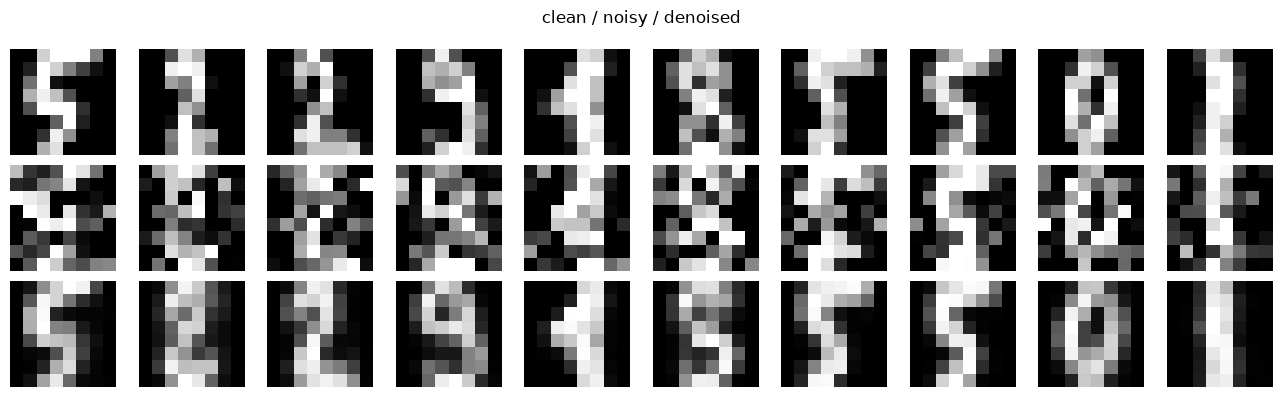

In [6]:
dae = AE(32, hidden=128); fit(dae, plain_loss, epochs=80, noise=0.4); plain = AE(32, hidden=128); fit(plain, plain_loss, epochs=80)
torch.manual_seed(5); noisy = (Xte + .4 * torch.randn_like(Xte)).clamp(0, 1)
with torch.no_grad(): e_noisy = F.mse_loss(noisy, Xte).item(); e_dae = F.mse_loss(dae(noisy), Xte).item(); e_plain = F.mse_loss(plain(noisy), Xte).item()
print(f"MSE to clean image  noisy input: {e_noisy:.4f}  plain AE(noisy): {e_plain:.4f}  denoising AE(noisy): {e_dae:.4f}")
check(e_dae < e_noisy and e_dae < e_plain, "denoising AE removes noise better than the noisy input or a plain AE")
with torch.no_grad(): den = dae(noisy[:10])
fig, ax = plt.subplots(3, 10, figsize=(13, 4))
for i in range(10):
    for r_, im in enumerate([Xte[i], noisy[i], den[i]]): ax[r_, i].imshow(im.view(8, 8), cmap="gray"); ax[r_, i].axis("off")
plt.suptitle("clean / noisy / denoised"); show("denoising_ae"); METRICS.update(dae_mse=e_dae, noisy_mse=e_noisy)

## 6 · Contractive autoencoder
Penalise the Frobenius norm of the encoder Jacobian, $\|\partial z/\partial x\|_F^2$, to make the code locally *insensitive* to input perturbations. For a single sigmoid layer $z=\sigma(Wx+b)$ it has the closed form $\sum_j(z_j(1-z_j))^2\|W_j\|^2$, which we verify with autograd's Jacobian.

In [7]:
W_ = torch.randn(5, 64); b_ = torch.randn(5); x0 = torch.rand(64)
J = torch.autograd.functional.jacobian(lambda x: torch.sigmoid(W_ @ x + b_), x0); z0 = torch.sigmoid(W_ @ x0 + b_)
closed = ((z0 * (1 - z0)) ** 2 * (W_ ** 2).sum(1)).sum()
check(torch.isclose((J ** 2).sum(), closed, rtol=1e-4), "closed-form contractive penalty == ||Jacobian||_F² from autograd")
class CAE(nn.Module):
    def __init__(s, k=16): super().__init__(); s.e = nn.Linear(64, k); s.d = nn.Sequential(nn.Linear(k, 64), nn.Sigmoid())
    def encode(s, x): return torch.sigmoid(s.e(x))
    def forward(s, x): return s.d(s.encode(x))
def cae_loss(lam): 
    def f(m, xin, xt): z = m.encode(xin); pen = (((z * (1 - z)) ** 2) @ (m.e.weight ** 2).sum(1)).mean(); return F.mse_loss(m.d(z), xt) + lam * pen
    return f
def sens(m, X, eps=.05):
    with torch.no_grad(): return (m.encode(X + eps * torch.randn_like(X)) - m.encode(X)).norm(dim=1).mean().item()
cm, pm = CAE(), CAE(); fit(cm, cae_loss(1.0), epochs=80); fit(pm, cae_loss(0.0), epochs=80)
print(f"latent sensitivity to input noise:  contractive {sens(cm, Xte):.4f}   ordinary {sens(pm, Xte):.4f}")
check(sens(cm, Xte) < sens(pm, Xte), "contractive penalty reduces latent sensitivity")

  ✅ closed-form contractive penalty == ||Jacobian||_F² from autograd


latent sensitivity to input noise:  contractive 0.0002   ordinary 0.1656
  ✅ contractive penalty reduces latent sensitivity


## 7 · Latent geometry and downstream usefulness
A representation is good if it makes *other* tasks easy. We never used labels to train the encoders. We (i) project a 2-D bottleneck code to a plot, coloured by class, and (ii) fit a **linear probe** (logistic regression) and kNN on the learned 16-d codes vs raw pixels and PCA.

18:16:41 | INFO | figure saved -> figures/latent_2d.png


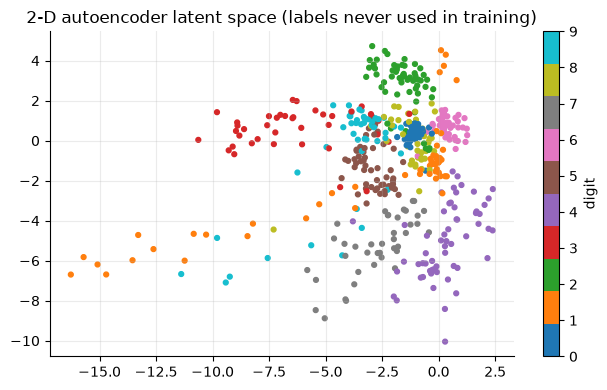

raw pixels (64)        linear probe 0.978   5-NN 0.982
PCA-16                 linear probe 0.968   5-NN 0.992


AE-16                  linear probe 0.964   5-NN 0.982
random projection-16   linear probe 0.817   5-NN 0.924
  ✅ learned 16-d code is better for kNN than a random 16-d projection
  ✅ linear probe on the AE code exceeds 85%


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
ae2 = AE(2, hidden=128); fit(ae2, plain_loss, epochs=150)
with torch.no_grad(): z2 = ae2.encode(Xte).numpy()
sc = plt.scatter(z2[:, 0], z2[:, 1], c=yte, cmap="tab10", s=12); plt.colorbar(sc, label="digit"); plt.title("2-D autoencoder latent space (labels never used in training)"); show("latent_2d")
ae16 = AE(16, hidden=128); fit(ae16, plain_loss, epochs=100); pca16 = PCA(16).fit(Xtr.numpy())
reps = {"raw pixels (64)": (Xtr.numpy(), Xte.numpy()), "PCA-16": (pca16.transform(Xtr.numpy()), pca16.transform(Xte.numpy())),
        "AE-16": tuple(ae16.encode(a).detach().numpy() for a in (Xtr, Xte)), "random projection-16": (lambda R: (Xtr.numpy() @ R, Xte.numpy() @ R))(np.random.default_rng(0).normal(size=(64, 16)) / 4)}
res = {}
for nme, (a, b) in reps.items():
    lp = LogisticRegression(max_iter=3000).fit(a, ytr).score(b, yte); kn = KNeighborsClassifier(5).fit(a, ytr).score(b, yte); res[nme] = (lp, kn); print(f"{nme:22s} linear probe {lp:.3f}   5-NN {kn:.3f}")
check(res["AE-16"][1] > res["random projection-16"][1], "learned 16-d code is better for kNN than a random 16-d projection")
check(res["AE-16"][0] > .85, "linear probe on the AE code exceeds 85%")
METRICS["probe_acc"] = {k: v[0] for k, v in res.items()}

In [9]:
save_metrics("16", METRICS)
log.info('notebook 16 finished OK')

18:16:47 | INFO | metrics saved -> metrics.json


18:16:47 | INFO | notebook 16 finished OK


## Wrap-up

## Exercises (do these next)

1. Plot the *interpolation* between two digits in latent space vs pixel space; which looks more natural?
2. Train a stacked (deep) AE with batch-norm and compare to the shallow AE at equal parameter count.
3. Measure how kNN accuracy on AE codes changes as the code size shrinks to 2.

## Where to read more

- Wiki chapter: [Module 16](https://github.com/anuxlab/deep-learning-systems/wiki/Module-16) (derivations, worked example, Q&A).
- Hinton & Salakhutdinov (2006); Baldi & Hornik (1989) linear AEs & PCA; Vincent et al. (2008) DAE; Rifai et al. (2011) CAE; Ng, *Sparse autoencoder* notes.